## Preparation

In [169]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder

## Load Dataset

In [170]:
columns = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education-num",
    "marital-status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital-gain",
    "capital-loss",
    "hours-per-week",
    "native",
    "income",
]

df = pd.read_csv(
    "adult.data",
    names=columns,
    skipinitialspace=True,
    na_values="?")

## Tahap EDA

In [171]:
# Data Exploration
print("Informasi dataset")
df.info()

Informasi dataset
<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       30725 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education-num   32561 non-null  int64
 5   marital-status  32561 non-null  str  
 6   occupation      30718 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital-gain    32561 non-null  int64
 11  capital-loss    32561 non-null  int64
 12  hours-per-week  32561 non-null  int64
 13  native          31978 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [172]:
print("Deskripsi statistik")
df.describe()

Deskripsi statistik


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [173]:
print("Nama - nama kolom")
df.columns

Nama - nama kolom


Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native', 'income'],
      dtype='str')

In [174]:
print(f"Dataset ini berisi {df.shape[0]} baris dan {df.shape[1]} kolom.")

Dataset ini berisi 32561 baris dan 15 kolom.


In [175]:
print("5 data teratas")
df.head()

5 data teratas


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [176]:
df = df.drop_duplicates().reset_index(drop=True)
print("Jumlah duplikat setelah drop:", df.duplicated().sum())

print("\nProporsi target income : ")
print(df['income'].value_counts(normalize=True) * 100)

Jumlah duplikat setelah drop: 0

Proporsi target income : 
income
<=50K    75.907428
>50K     24.092572
Name: proportion, dtype: float64


In [177]:
# Missing Values
df.isnull().sum()

age                  0
workclass         1836
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native             582
income               0
dtype: int64

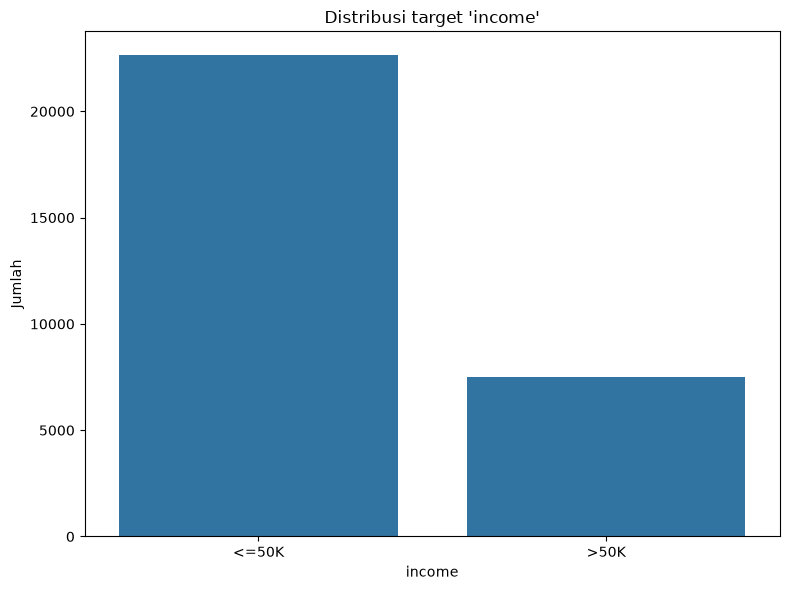

In [198]:
# Distribusi target
plt.figure(figsize=(8,6))
sns.countplot(data=df, x='income')
plt.title("Distribusi target 'income'")
plt.ylabel("Jumlah")
plt.tight_layout()
plt.show()

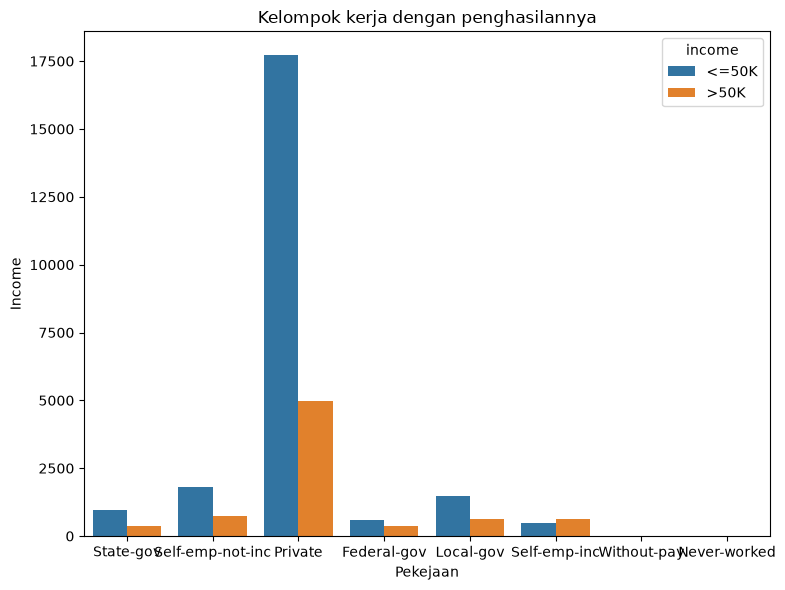

In [179]:
# Melihat kelompok pekerjaan mana yang paling banyak berpenghasilan >50k
plt.figure(figsize=(8,6))
sns.countplot(data=df, x="workclass", hue="income")
plt.title("Kelompok kerja dengan penghasilannya")
plt.xlabel("Pekejaan")
plt.ylabel("Income")
plt.tight_layout()
plt.show()

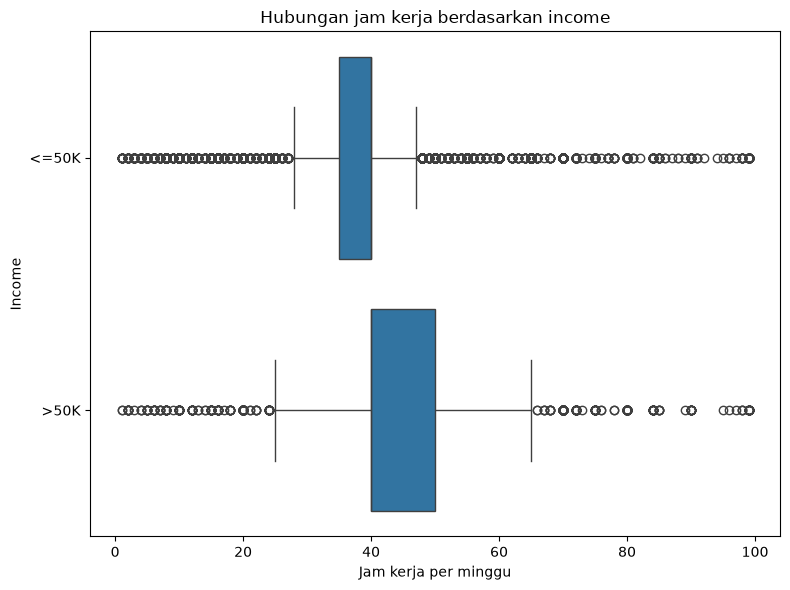

In [180]:
# Hubungan jam kerja berdasarkan income
plt.figure(figsize=(8,6))
sns.boxplot(data=df, x='hours-per-week', y='income')
plt.title("Hubungan jam kerja berdasarkan income")
plt.xlabel("Jam kerja per minggu")
plt.ylabel("Income")
plt.tight_layout()
plt.show()

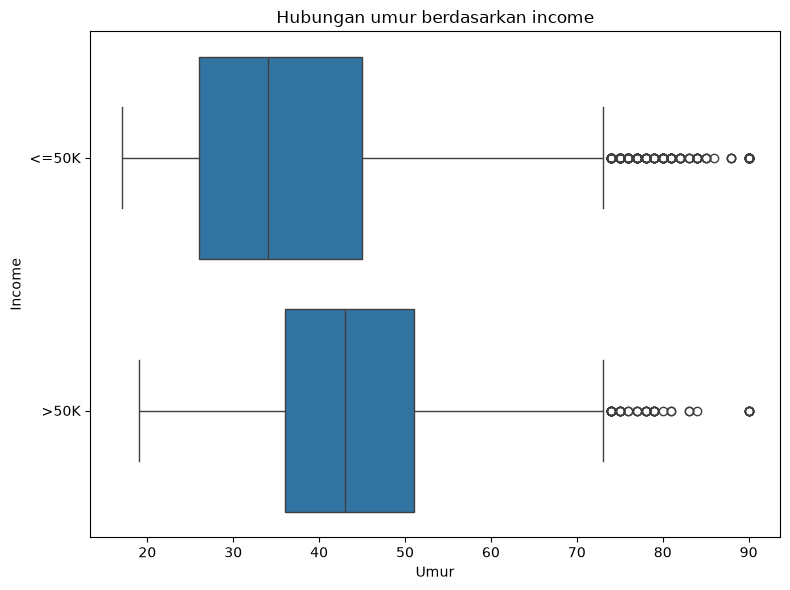

In [199]:
# Hubungan umur berdasarkan income
plt.figure(figsize=(8,6))
sns.boxplot(data=df, x='age', y='income')
plt.title("Hubungan umur berdasarkan income")
plt.xlabel("Umur")
plt.ylabel("Income")
plt.tight_layout()
plt.show()

##  Data Preprocessing

In [182]:
df.dropna(inplace=True)
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [183]:
# encoding feature gender
gender = LabelEncoder()
gender.fit(df['sex'])
df['sex_code'] = gender.transform(df['sex'])
df[['sex', 'sex_code']].head()

,sex,sex_code
0,Male,1
1,Male,1
2,Male,1
3,Male,1
4,Female,0


In [184]:
# encoding feature education
education = LabelEncoder()
education.fit(df['education'])
df['education_code'] = education.transform(df['education'])
df[['education', 'education_code']].head()

,education,education_code
0,Bachelors,9
1,Bachelors,9
2,HS-grad,11
3,11th,1
4,Bachelors,9


In [185]:
# encoding feature race
race = LabelEncoder()
race.fit(df['race'])
df['race_code'] = race.transform(df['race'])
df[['race', 'race_code']].head()

,race,race_code
0,White,4
1,White,4
2,White,4
3,Black,2
4,Black,2


In [186]:
# encoding feature workclass
workclass = LabelEncoder()
workclass.fit(df['workclass'])
df['workclass_code'] = workclass.transform(df['workclass'])
df[['workclass', 'workclass_code']].head()

,workclass,workclass_code
0,State-gov,5
1,Self-emp-not-inc,4
2,Private,2
3,Private,2
4,Private,2


In [187]:
# encoding feature occupation
occupation = LabelEncoder()
occupation.fit(df['occupation'])
df['occupation_code'] = occupation.transform(df['occupation'])
df[['occupation', 'occupation_code']].head()

,occupation,occupation_code
0,Adm-clerical,0
1,Exec-managerial,3
2,Handlers-cleaners,5
3,Handlers-cleaners,5
4,Prof-specialty,9


In [188]:
# encoding feature relationship
relationship = LabelEncoder()
relationship.fit(df['relationship'])
df['relationship_code'] = relationship.transform(df['relationship'])
df[['relationship', 'relationship_code']].head()

,relationship,relationship_code
0,Not-in-family,1
1,Husband,0
2,Not-in-family,1
3,Husband,0
4,Wife,5


In [189]:
# encoding feature native
native = LabelEncoder()
native.fit(df['native'])
df['native_code'] = native.transform(df['native'])
df[['native', 'native_code']].head()

,native,native_code
0,United-States,38
1,United-States,38
2,United-States,38
3,United-States,38
4,Cuba,4


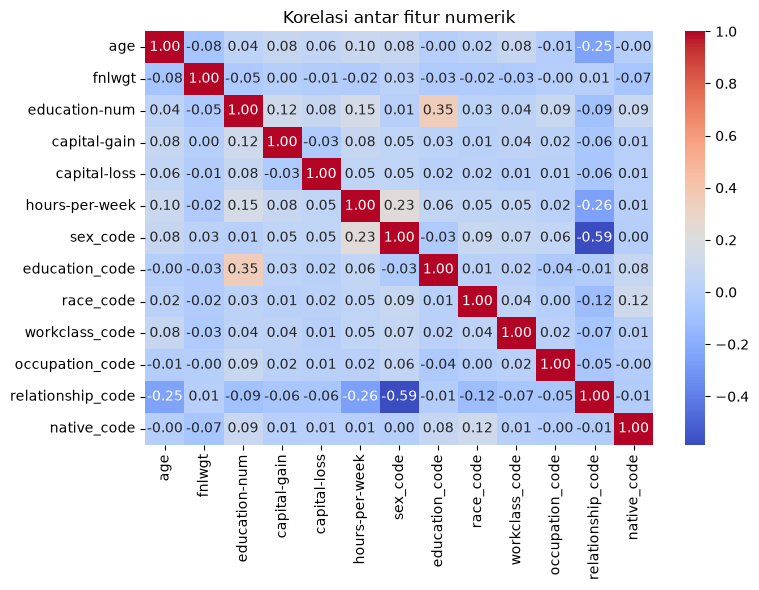

In [190]:
# Membuat heatmap untuk mengukur korelasi antar fitur numerik
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm', cbar=True, annot=True, fmt='.2f')
plt.title("Korelasi antar fitur numerik")
plt.tight_layout()
plt.show()

## Feature Engineering

In [191]:
X = df[['fnlwgt', 'workclass_code', 'education_code','occupation_code', 'relationship_code', 'race_code', 'sex_code', 'native_code']]
y = df['income']

In [192]:
X.head()

,fnlwgt,workclass_code,education_code,occupation_code,relationship_code,race_code,sex_code,native_code
0,77516,5,9,0,1,4,1,38
1,83311,4,9,3,0,4,1,38
2,215646,2,11,5,1,4,1,38
3,234721,2,1,5,0,2,1,38
4,338409,2,9,9,5,2,0,4


## Split Data

In [193]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=67
)

## Modeling

In [194]:
# membuat model random forest
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=67
    )

# melatih model
rf.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",67
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [195]:
# membuat prediksi
y_pred = rf.predict(X_test)
y_pred

array(['<=50K', '>50K', '<=50K', ..., '<=50K', '<=50K', '>50K'],
      shape=(6028,), dtype=object)

## Evaluation

In [196]:
# menghitung akurasi model menggunakan beberapa metrics
print("="*15)
print("AKURASI MODEL")
print("="*15)
print(f"Akurasi : {accuracy_score(y_test, y_pred)*100:.2f}")
print(f"Classification Report : \n{classification_report(y_test, y_pred)}")

AKURASI MODEL
Akurasi : 82.83
Classification Report : 
              precision    recall  f1-score   support

       <=50K       0.86      0.93      0.89      4568
        >50K       0.69      0.52      0.60      1460

    accuracy                           0.83      6028
   macro avg       0.78      0.72      0.74      6028
weighted avg       0.82      0.83      0.82      6028



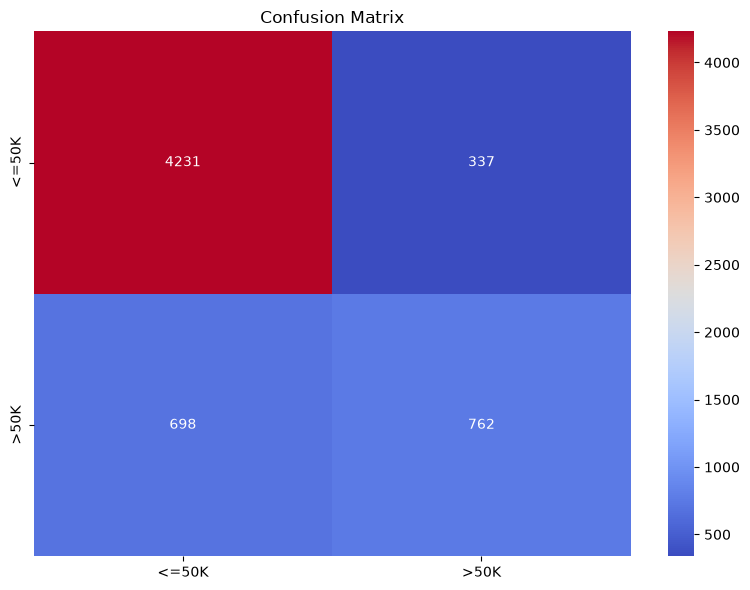

In [197]:
# membuat confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, xticklabels=rf.classes_, yticklabels=rf.classes_, cmap="coolwarm", cbar=True, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()